<a href="https://colab.research.google.com/github/vikavikylia/ML/blob/main/%D0%9B%D0%A02_3_%D0%AE%D0%B7%D1%8C%D0%BA%D0%BE%D0%B2%D0%B0_%D0%A4%D0%86%D0%A2_3_12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Лабораторна робота №2_3
(Була присутня на парі)

In [6]:
import pandas as pd
import numpy as np
import requests
import matplotlib.pyplot as plt
import seaborn as sns
import re

from io import StringIO
from urllib.parse import quote

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.family"] = "DejaVu Sans"

In [11]:
url = "https://uk.wikipedia.org/wiki/" + quote("Населення_України")

response = requests.get(
    url,
    headers={"User-Agent": "Mozilla/5.0"},
    timeout=30
)
response.raise_for_status()

tables = pd.read_html(StringIO(response.text))

print("кількість таблиць на сторінці:", len(tables))

#шукаємо таблицю з регіонами та роками
regional_table = None
best_year_count = 0

for i, table in enumerate(tables):
    columns = [
        str(col[-1] if isinstance(col, tuple) else col).strip()
        for col in table.columns
    ]

    has_region = any(
        "регіон" in col.lower() or "область" in col.lower()
        for col in columns
    )

    years = [
        col for col in columns
        if re.fullmatch(r"(19|20)\d{2}", col)
    ]

    if has_region and len(years) > best_year_count:
        regional_table = table.copy()
        best_year_count = len(years)
        selected_table_number = i

if regional_table is None:
    raise ValueError(
        "не вдалося автоматично знайти таблицю з регіонами"
        "перевір таблиці на сторінці"
    )

print("номер знайденої таблиці:", selected_table_number)
print("кількість стовпців-років:", best_year_count)
print("\nпочаток знайденої таблиці:")
print(regional_table.head().to_string(index=False))

кількість таблиць на сторінці: 70
номер знайденої таблиці: 34
кількість стовпців-років: 9

початок знайденої таблиці:
  Область/Регіон  1926  1939  1959  1970  1979  1989  2001  2014 2019
       Вінницька 112.0 119.0   170   254   344   439   459   500  517
       Волинська   NaN 163.0   259   321   392   486   498   518  523
Дніпропетровська 221.0 531.0   702   762   803   832   829   835  840
        Донецька 394.0 780.0   858   874   890   902   900   906  909
     Житомирська 163.0 205.0   258   349   439   529   556   584  593


In [13]:
#спрощуємо назви стовпців
regional_table.columns = [
    str(col[-1] if isinstance(col, tuple) else col).strip()
    for col in regional_table.columns
]

#знаходимо стовпець із назвами регіонів
region_col = next(
    col for col in regional_table.columns
    if "регіон" in col.lower() or "область" in col.lower()
)

#знаходимо стовпці з роками
year_cols = [
    col for col in regional_table.columns
    if re.fullmatch(r"(19|20)\d{2}", col)
]

#залишаємо назви регіонів і роки
data = regional_table[[region_col] + year_cols].copy()
data = data.rename(columns={region_col: "регіон"})

#очищуємо значення та перетворюємо їх на числа
for col in year_cols:
    data[col] = (
        data[col]
        .astype(str)
        .str.replace('\xa0', '', regex=False)
        .str.replace(' ', '', regex=False)
        .str.replace(',', '.', regex=False)
        .str.replace('−', '-', regex=False)
        .replace(['-', '—', '–', 'nan', 'None', ''], np.nan)
    )
    data[col] = pd.to_numeric(data[col], errors='coerce')

data["регіон"] = data["регіон"].astype(str).str.strip()

#прибираємо порожні рядки та загальні підсумки, якщо вони є
data = data.dropna(subset=["регіон"])
data = data[
    ~data["регіон"].str.lower().str.contains(
        r"^україна$|^всього$|^разом$|^усього$",
        regex=True
    )
].copy()

#перетворюємо таблицю з широкого формату в довгий
long_data = data.melt(
    id_vars="регіон",
    value_vars=year_cols,
    var_name="рік",
    value_name="коефіцієнт народжуваності"
)

long_data["рік"] = long_data["рік"].astype(int)
long_data = long_data.dropna(
    subset=["коефіцієнт народжуваності"]
)

print("розмір початкової регіональної таблиці:", data.shape)
print("кількість регіонів:", data["регіон"].nunique())
print("роки у таблиці:", sorted(long_data["рік"].unique()))
print("\nпідготовлені дані:")
print(long_data.head(10).to_string(index=False))

розмір початкової регіональної таблиці: (26, 10)
кількість регіонів: 26
роки у таблиці: [np.int64(1926), np.int64(1939), np.int64(1959), np.int64(1970), np.int64(1979), np.int64(1989), np.int64(2001), np.int64(2014), np.int64(2019)]

підготовлені дані:
          регіон  рік  коефіцієнт народжуваності
       Вінницька 1926                      112.0
Дніпропетровська 1926                      221.0
        Донецька 1926                      394.0
     Житомирська 1926                      163.0
      Запорізька 1926                      116.0
        Київська 1926                       90.0
  Кіровоградська 1926                      108.0
       Луганська 1926                      216.0
    Миколаївська 1926                      179.0
         Одеська 1926                      379.0


In [14]:
print("ІНФОРМАЦІЯ ПРО ДАНІ")
print("-" * 45)

print("\nтипи даних:")
print(long_data.dtypes)

print("\nкількість пропущених значень:")
print(long_data.isna().sum())

print("\nкількість записів:", len(long_data))
print("кількість регіонів:", long_data["регіон"].nunique())
print("кількість років:", long_data["рік"].nunique())

print("\nописова статистика:")
print(
    long_data["коефіцієнт народжуваності"]
    .describe()
    .round(3)
)

print("\nсередній коефіцієнт за роками:")
print(
    long_data.groupby("рік")["коефіцієнт народжуваності"]
    .mean()
    .round(3)
)

print("\nсередній коефіцієнт за регіонами:")
print(
    long_data.groupby("регіон")["коефіцієнт народжуваності"]
    .mean()
    .sort_values(ascending=False)
    .round(3)
)

ІНФОРМАЦІЯ ПРО ДАНІ
---------------------------------------------

типи даних:
регіон                        object
рік                            int64
коефіцієнт народжуваності    float64
dtype: object

кількість пропущених значень:
регіон                       0
рік                          0
коефіцієнт народжуваності    0
dtype: int64

кількість записів: 225
кількість регіонів: 26
кількість років: 9

описова статистика:
count     225.000
mean      504.853
std       232.756
min        90.000
25%       346.000
50%       516.000
75%       655.000
max      1000.000
Name: коефіцієнт народжуваності, dtype: float64

середній коефіцієнт за роками:
рік
1926    232.895
1939    316.320
1959    406.231
1970    482.000
1979    543.269
1989    604.962
2001    611.731
2014    632.000
2019    638.960
Name: коефіцієнт народжуваності, dtype: float64

середній коефіцієнт за регіонами:
регіон
Київ                  1000.000
Донецька               823.667
Луганська              755.444
Дніпропетровська 

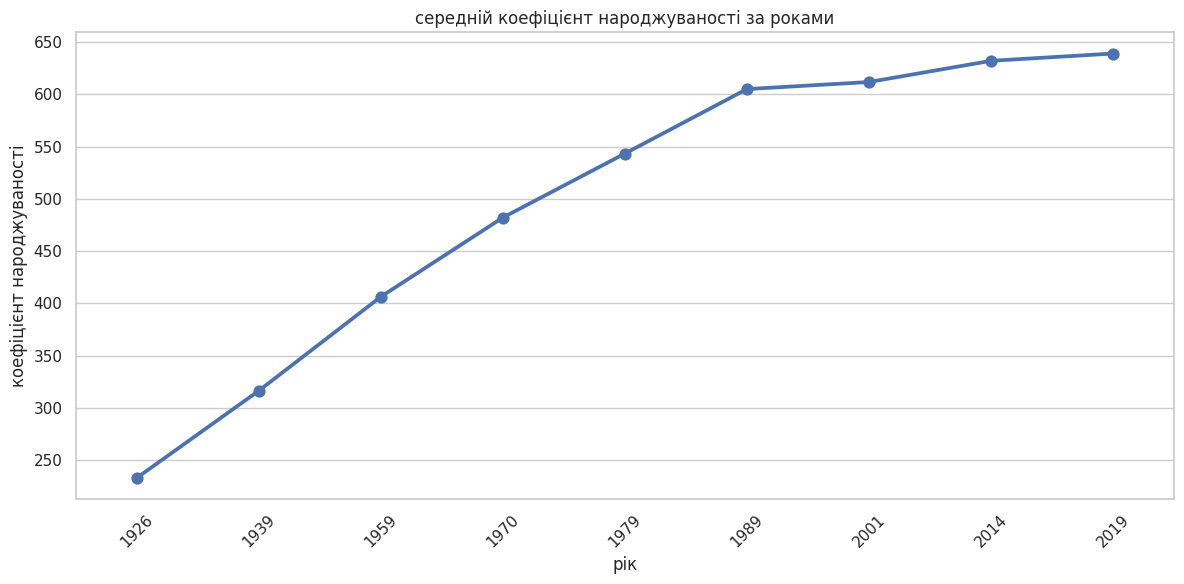

In [19]:
plt.figure(figsize=(12, 6))

sns.pointplot(
    data=long_data,
    x="рік",
    y="коефіцієнт народжуваності",
    errorbar=None
)

plt.title("середній коефіцієнт народжуваності за роками")
plt.xlabel("рік")
plt.ylabel("коефіцієнт народжуваності")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

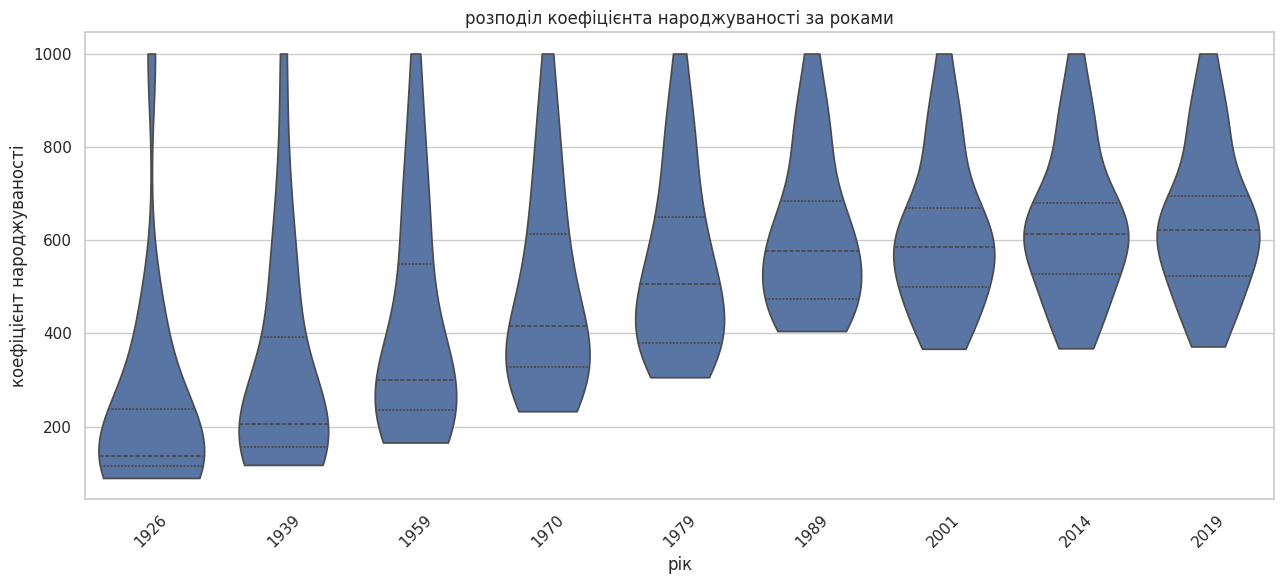

In [18]:
plt.figure(figsize=(13, 6))

sns.violinplot(
    data=long_data,
    x="рік",
    y="коефіцієнт народжуваності",
    inner="quartile",
    cut=0
)

plt.title("розподіл коефіцієнта народжуваності за роками")
plt.xlabel("рік")
plt.ylabel("коефіцієнт народжуваності")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

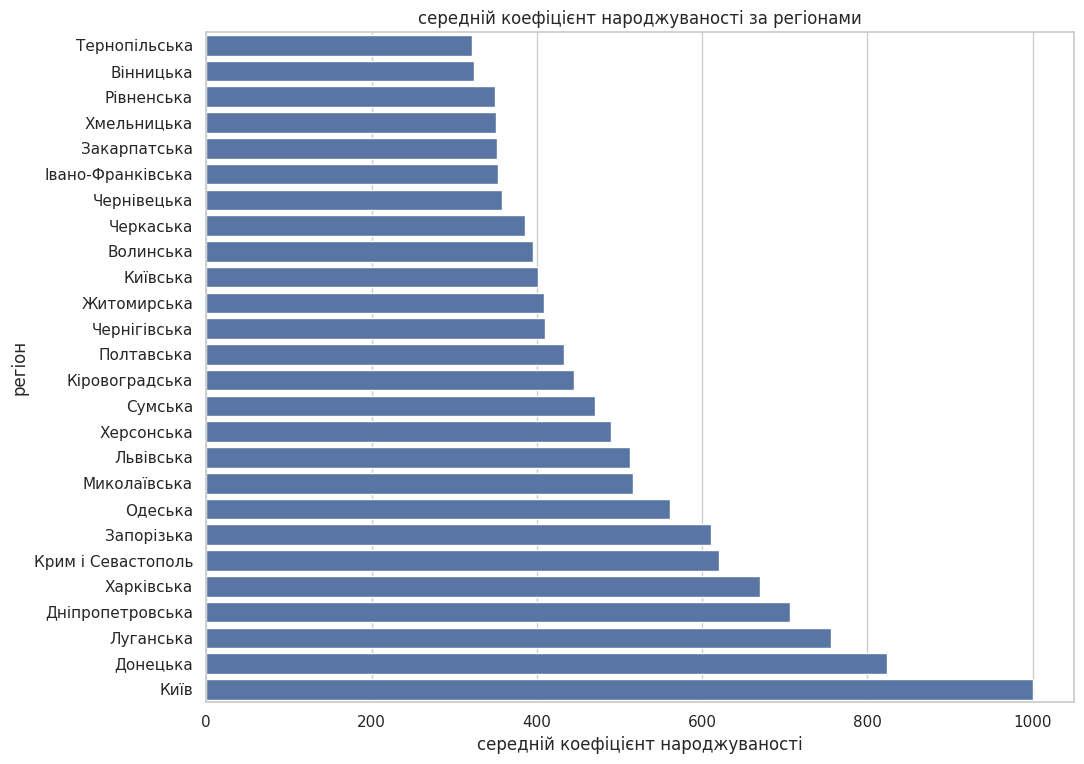

In [20]:
region_means = (
    long_data.groupby("регіон")["коефіцієнт народжуваності"]
    .mean()
    .sort_values()
    .reset_index()
)

plt.figure(figsize=(11, max(6, len(region_means) * 0.3)))

sns.barplot(
    data=region_means,
    x="коефіцієнт народжуваності",
    y="регіон"
)

plt.title("середній коефіцієнт народжуваності за регіонами")
plt.xlabel("середній коефіцієнт народжуваності")
plt.ylabel("регіон")
plt.tight_layout()
plt.show()

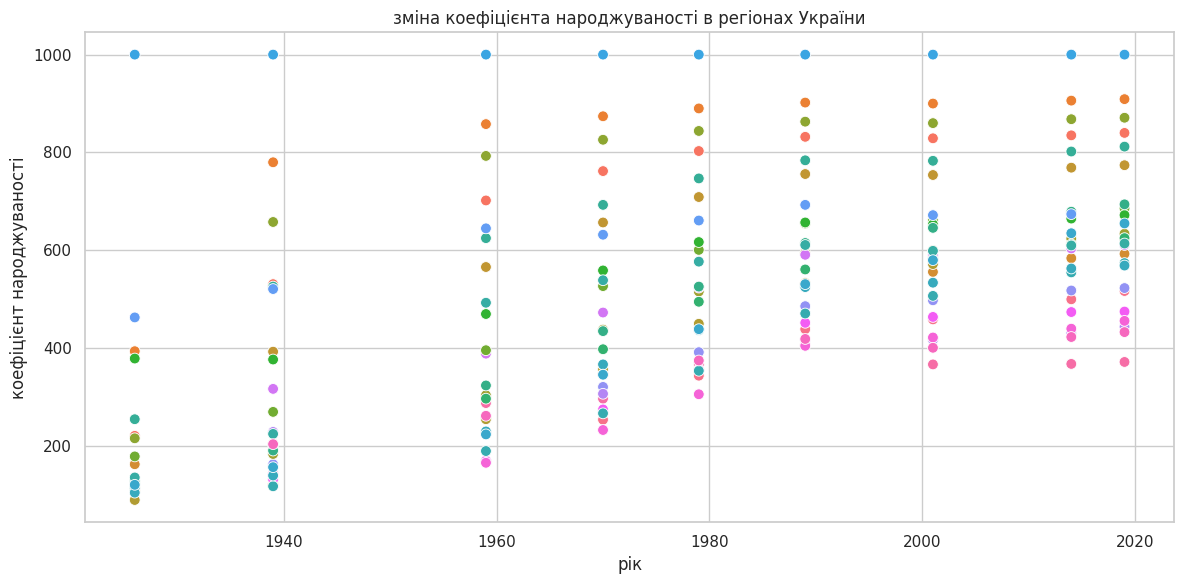

In [21]:
plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=long_data,
    x="рік",
    y="коефіцієнт народжуваності",
    hue="регіон",
    legend=False,
    s=60
)

plt.title("зміна коефіцієнта народжуваності в регіонах України")
plt.xlabel("рік")
plt.ylabel("коефіцієнт народжуваності")
plt.tight_layout()
plt.show()

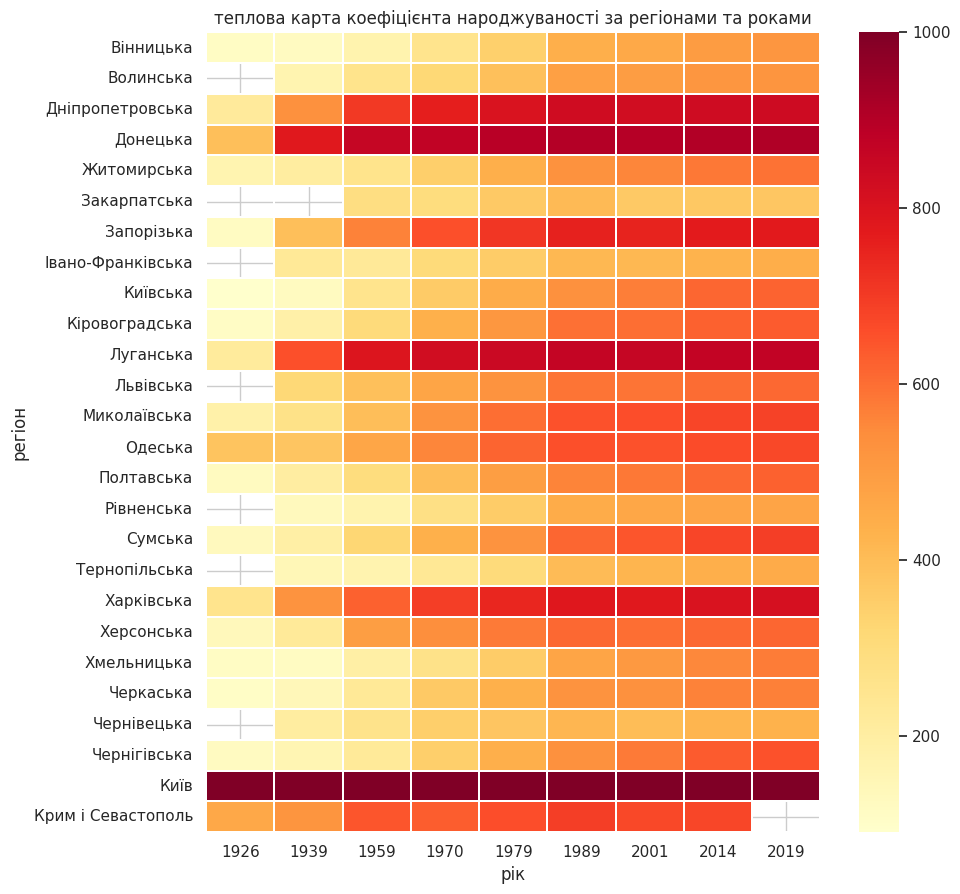

In [22]:
heatmap_data = data.set_index("регіон")[year_cols].copy()

plt.figure(
    figsize=(max(10, len(year_cols) * 0.8),
             max(7, len(heatmap_data) * 0.35))
)

sns.heatmap(
    heatmap_data,
    annot=False,
    cmap="YlOrRd",
    linewidths=0.3
)

plt.title("теплова карта коефіцієнта народжуваності за регіонами та роками")
plt.xlabel("рік")
plt.ylabel("регіон")
plt.tight_layout()
plt.show()

In [23]:
print("ПІДСУМКИ АНАЛІЗУ")
print("-" * 45)

print("період у даних:",
      long_data["рік"].min(), "—", long_data["рік"].max())

print("кількість регіонів:", long_data["регіон"].nunique())

print("середнє значення коефіцієнта:",
      round(long_data["коефіцієнт народжуваності"].mean(), 3))

print("мінімальне значення:")
print(
    long_data.loc[
        long_data["коефіцієнт народжуваності"].idxmin()
    ].to_string()
)

print("\nмаксимальне значення:")
print(
    long_data.loc[
        long_data["коефіцієнт народжуваності"].idxmax()
    ].to_string()
)

print("\nсередній коефіцієнт за регіонами:")
print(
    long_data.groupby("регіон")["коефіцієнт народжуваності"]
    .mean()
    .sort_values(ascending=False)
    .round(3)
    .to_string()
)

ПІДСУМКИ АНАЛІЗУ
---------------------------------------------
період у даних: 1926 — 2019
кількість регіонів: 26
середнє значення коефіцієнта: 504.853
мінімальне значення:
регіон                       Київська
рік                              1926
коефіцієнт народжуваності        90.0

максимальне значення:
регіон                         Київ
рік                            1926
коефіцієнт народжуваності    1000.0

середній коефіцієнт за регіонами:
регіон
Київ                  1000.000
Донецька               823.667
Луганська              755.444
Дніпропетровська       706.111
Харківська             669.667
Крим і Севастополь     620.125
Запорізька             610.444
Одеська                561.000
Миколаївська           516.889
Львівська              512.250
Херсонська             489.333
Сумська                471.000
Кіровоградська         444.778
Полтавська             432.889
Чернігівська           409.778
Житомирська            408.444
Київська               401.778
Волинська    